#### Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

### Data Loading

#### 1. Load main flight data


In [2]:
years = range(2004,2009)
files = [f"{year}.csv" for year in years]

#### 2. Combine all years into one DataFrame

In [3]:
# List to hold individual dataframes
flight_dfs = []

for file in files:
    # Read only necessary columns to save memory
    df = pd.read_csv(
        file,
        usecols=[
            "Year", "Month", "DayOfWeek", "DepTime", "CRSDepTime",
            "ArrDelay", "TailNum", "Diverted", "Distance", "UniqueCarrier"
        ]
    )
    flight_dfs.append(df)

# Combine all years into one DataFrame
flights = pd.concat(flight_dfs, ignore_index=True)

# Load Supplementary Data
airports = pd.read_csv("airports.csv")
carriers = pd.read_csv("carriers.csv")
planes   = pd.read_csv("plane-data.csv")

### a) Best times & days of the wheel to minimise delays each year

#### 1. Pre-processing
- Filter out missing arrival delays
- Create schedules departure hour (floor division by 100)
- Keep only hours between 0 and 23
- Group by Year, DayofWeek, DepHour
- Remove slots with fewer than 30 flights to remove unreliable estimates

In [4]:
delay_data = flights.dropna(subset=['ArrDelay']).copy()

delay_data['DepHour'] = (delay_data['CRSDepTime']//100).astype(int)

delay_data = delay_data[(delay_data['DepHour'] >= 0) & (delay_data['DepHour'] <= 23)]

delay_summary = (
                 delay_data.groupby(['Year', 'DayOfWeek', 'DepHour'])
                  .agg(AvgDelay=('ArrDelay', 'mean'),
                       FlightCount=('ArrDelay', 'count'))
                       .reset_index()
)

delay_summary = delay_summary[delay_summary['FlightCount']>=30]

#### 2. Best times table 
- Map day numbers to names eg assuming Monday = 1, Sunday =7 etc

In [5]:
day_names = {1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat', 7: 'Sun'}

best_times = (
    delay_summary
    .loc[delay_summary.groupby('Year')['AvgDelay'].idxmin()]
    [['Year', 'DayOfWeek', 'DepHour', 'AvgDelay']]
    .copy()
)
best_times['Day'] = best_times['DayOfWeek'].map(day_names)
best_times['AvgDelay'] = best_times['AvgDelay'].round(2)
best_times = best_times[['Year', 'Day', 'DepHour', 'AvgDelay']]

print("Best departure times (minimum average delay) per year:")
print(best_times.to_string(index=False))

Best departure times (minimum average delay) per year:
 Year Day  DepHour  AvgDelay
 2004 Mon        2     -6.82
 2005 Sun        5     -2.38
 2006 Thu        4     -4.62
 2007 Wed        3     -2.70
 2008 Tue        4     -8.09


#### 3. Plot Heatmap
- Prepare a mapping for day names on the y-axis
- set up the figure such that it is 2 columns with enough rows
-  Create pivot table: rows = DayOfWeek, columns = DepHour, values = AvgDelay
- Plot heatmap and adjust such that we can remove any unused plots

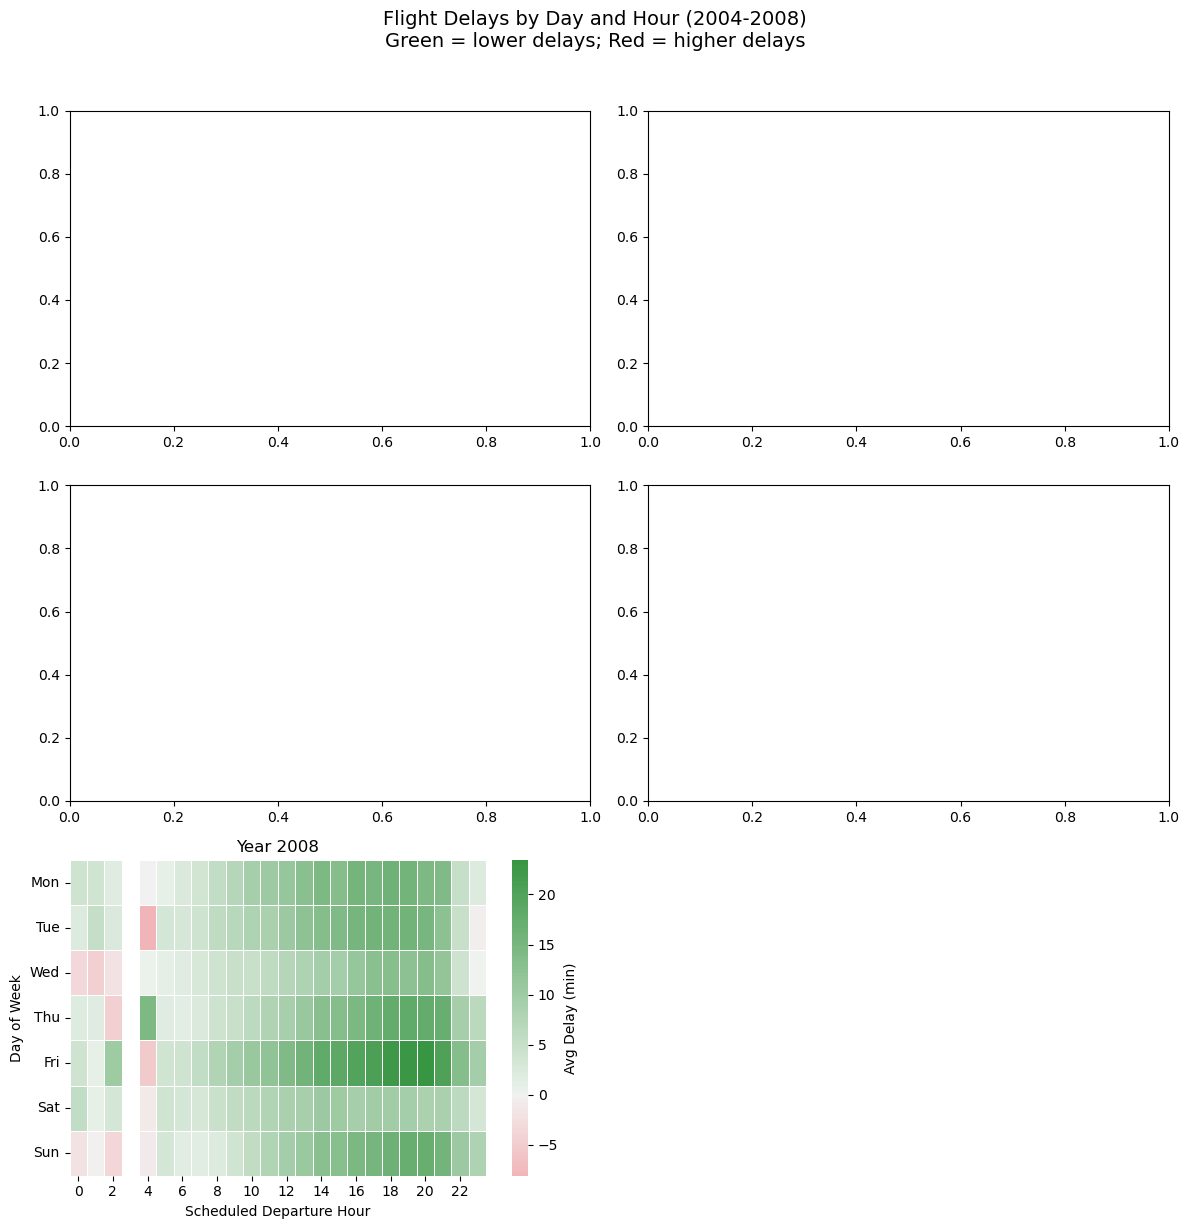

In [6]:
years = sorted(delay_summary['Year'].unique())
n_years = len(years)

n_cols = 2
n_rows = (n_years + 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12,4 * n_rows))
axes = axes.flatten() 

#colour palette
cmap = sns.diverging_palette(10, 130, s=80, l=55, as_cmap=True)

for i, year in enumerate(years):
    ax=axes[i] #subset data for the year
    year_data = delay_summary[delay_summary['Year'] == year] 
   
#create pivot table
pivot = year_data.pivot(index='DayOfWeek', columns='DepHour', values='AvgDelay')

#fill in missing hours with NaN 
pivot = pivot.reindex(columns=range(24), fill_value=np.nan)

#reindex hours 0-23 to ensure all appear
#sort days from Monday(1) to Sunday(7)
pivot = pivot.reindex(range(1, 8))

#Draw heatmap
sns.heatmap(pivot, ax=ax, cmap=cmap, center=0,
                cbar=True, cbar_kws={'label': 'Avg Delay (min)'},
                linewidths=0.5, linecolor='white')

ax.set_title(f'Year {year}')
ax.set_xlabel('Scheduled Departure Hour')
ax.set_ylabel('Day of Week')

#replace y-tick numbers with day names
ax.set_yticklabels([day_names[d] for d in range(1, 8)], rotation=0)

#remove unused subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Flight Delays by Day and Hour (2004-2008)\nGreen = lower delays; Red = higher delays',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

#### Conclusion for part a:
- In 2004-2008, Fridays emerge as the most congested day
- in 2004, heatmaps show significantly more green & yellow cells mainly during midday hours
- by 2004-2008, red zones expand significantly,starting earlier int he afternon and staying dark later into the night
- this shows that the flight network became less resilient to delays overtime
- 05:00 - 07:00 slots remain constantly green every year

### b) Evaluate whether older planes suffer more delays on a year-to-year basis.

#### 1. Clean plane data

In [7]:
plane_age_clean = planes.iloc[:, [0, 8]].copy()         
# TailNum (col1) and manufacture_year (col9)

plane_age_clean.columns = ['TailNum', 'manufacture_year']

plane_age_clean['TailNum'] = plane_age_clean['TailNum'].astype(str)
plane_age_clean['manufacture_year'] = pd.to_numeric(plane_age_clean['manufacture_year'], errors='coerce')

plane_age_clean = plane_age_clean[
    plane_age_clean['manufacture_year'].notna() &
    ~plane_age_clean['manufacture_year'].isin([0, 0.0]) &  # exclude 0 or 0000
    (plane_age_clean['manufacture_year'] > 1900)
]

#### 2. Prepare flights


In [8]:
flights_clean = flights[
    flights['TailNum'].notna() & (flights['TailNum'] != '') &
    flights['ArrDelay'].notna()
].copy()

flights_clean['TailNum'] = flights_clean['TailNum'].astype(str)

#### 3. Join and compute age of flights

In [9]:
age_analysis = pd.merge(flights_clean, plane_age_clean, on='TailNum', how='inner')

age_analysis['Age'] = age_analysis['Year'] - age_analysis['manufacture_year']

age_analysis = age_analysis[(age_analysis['Age'] >= 0) & (age_analysis['Age'] <= 50)]

#### 4. Age summary by group
- show average delay per year and age group

In [10]:
# Define age groups (bins and labels)
bins = [0, 5, 10, 15, 20, 25, 30, 50]
labels = ['0-5', '6-10', '11-15', '16-20', '21-25', '26-30', '30+']
age_analysis['AgeGroup'] = pd.cut(age_analysis['Age'], bins=bins, labels=labels, include_lowest=True)

age_summary = (
    age_analysis.groupby(['Year', 'AgeGroup'], observed=False)
    .agg(AvgDelay=('ArrDelay', 'mean'),
         FlightCount=('ArrDelay', 'count'))
    .reset_index()
)

#### 5. Plot
- plot average delay by group for each year in a bar chart

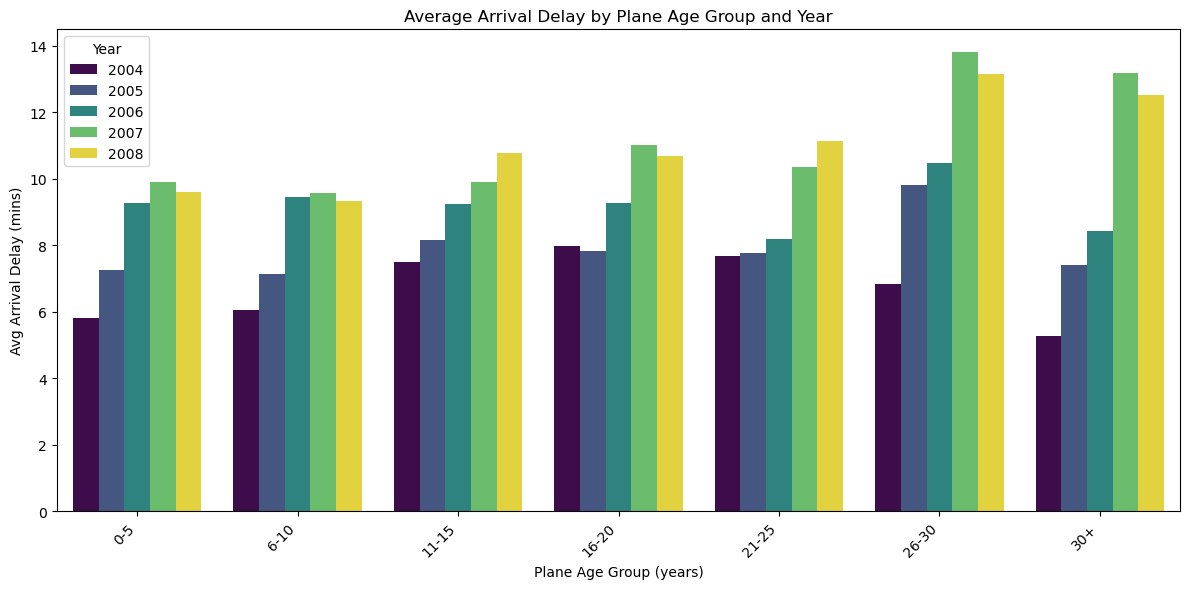

In [11]:
plt.figure(figsize=(12, 6))
sns.barplot(data=age_summary, x='AgeGroup', y='AvgDelay', hue='Year', palette='viridis')
plt.title('Average Arrival Delay by Plane Age Group and Year')
plt.subtitle = 'Age = flight year − plane manufacture year'
plt.xlabel('Plane Age Group (years)')
plt.ylabel('Avg Arrival Delay (mins)')
plt.legend(title='Year')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### 6. Plot trend line
- plot trend line for delay vs age per year with LOESS smoothed by:
- compute mean delay for each (Year,Age) combination before plotting

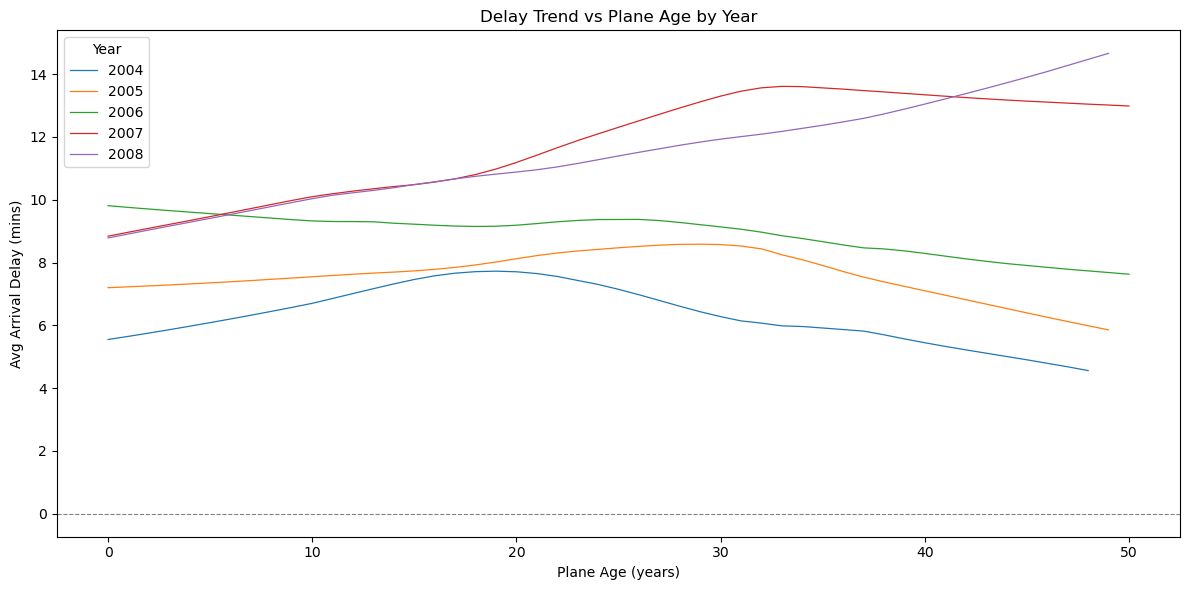

In [12]:
#mean
trend_data = (
    age_analysis.groupby(['Year', 'Age'], observed=False)
    ['ArrDelay']
    .mean()
    .reset_index(name='AvgDelay')
)

# Plot using LOESS smoothing per year
plt.figure(figsize=(12, 6))
years = sorted(trend_data['Year'].unique())
colors = sns.color_palette('tab10', len(years))

for year, color in zip(years, colors):
    subset = trend_data[trend_data['Year'] == year].sort_values('Age')
    if len(subset) < 5:   # need enough points for LOWESS
        continue
    # Apply LOWESS (fraction=0.5 gives moderate smoothing, adjust as needed)
    smoothed = lowess(subset['AvgDelay'], subset['Age'], frac=0.5, return_sorted=True)
    plt.plot(smoothed[:, 0], smoothed[:, 1], color=color, label=str(year), linewidth=0.9)

# Add horizontal line at y=0
plt.axhline(y=0, color='grey', linestyle='--', linewidth=0.8)
plt.title('Delay Trend vs Plane Age by Year')
plt.subtitle = 'Smoothed trend (LOESS) — positive = delayed on average'
plt.xlabel('Plane Age (years)')
plt.ylabel('Avg Arrival Delay (mins)')
plt.legend(title='Year')
plt.tight_layout()
plt.show()

#### Conclusion for part b:
- 2004 shows the 0-5 year age group consistently shows the lowest average arrival delays
- planes in 30+ years category from 2007 shows a dramatic spike in average delays
- this suggests that newer aircrafts are better liekly due to mechanical reliability & modern technology

### c) 

#### 1. Exploratory Data Analysis (EDA)

Diversion summary table

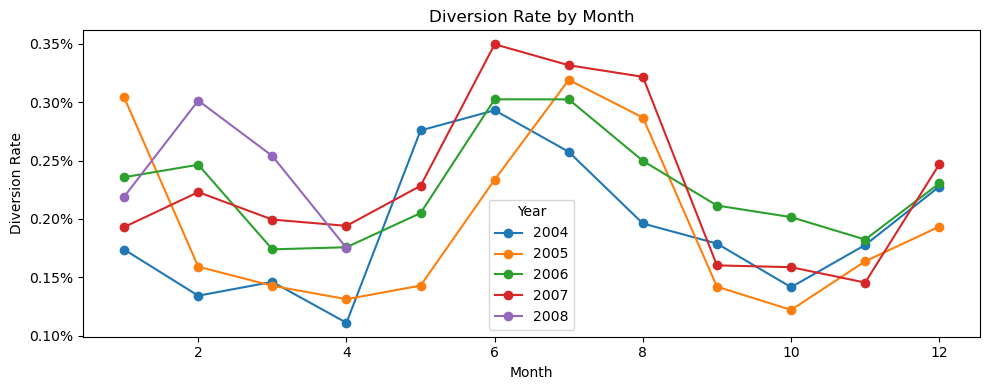

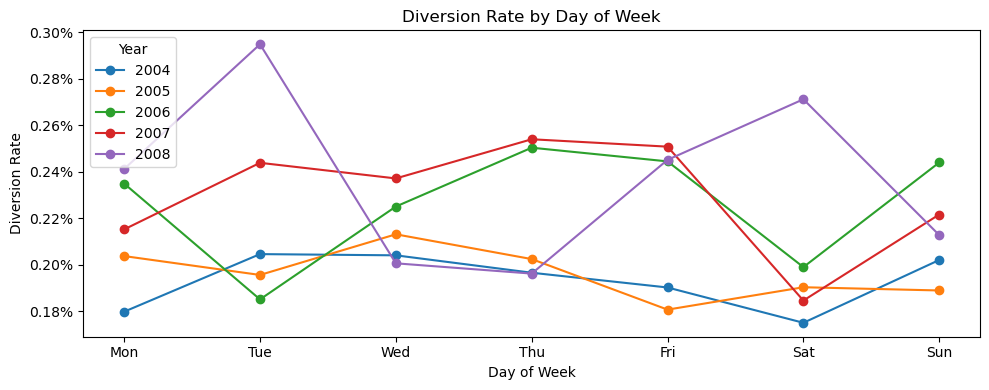

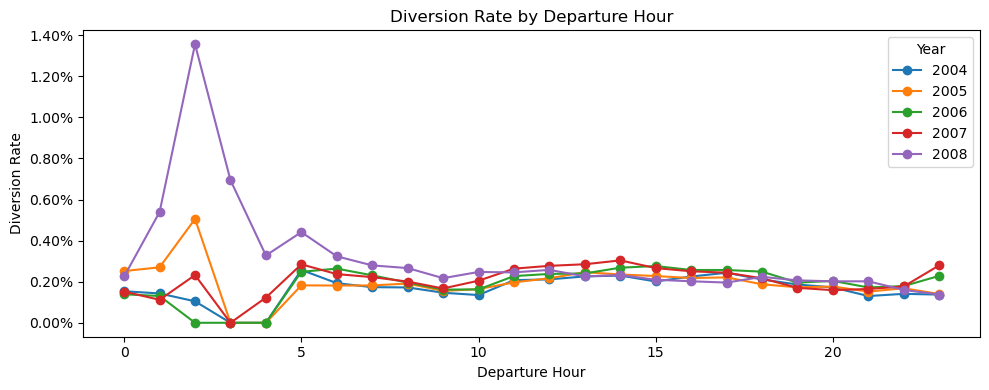

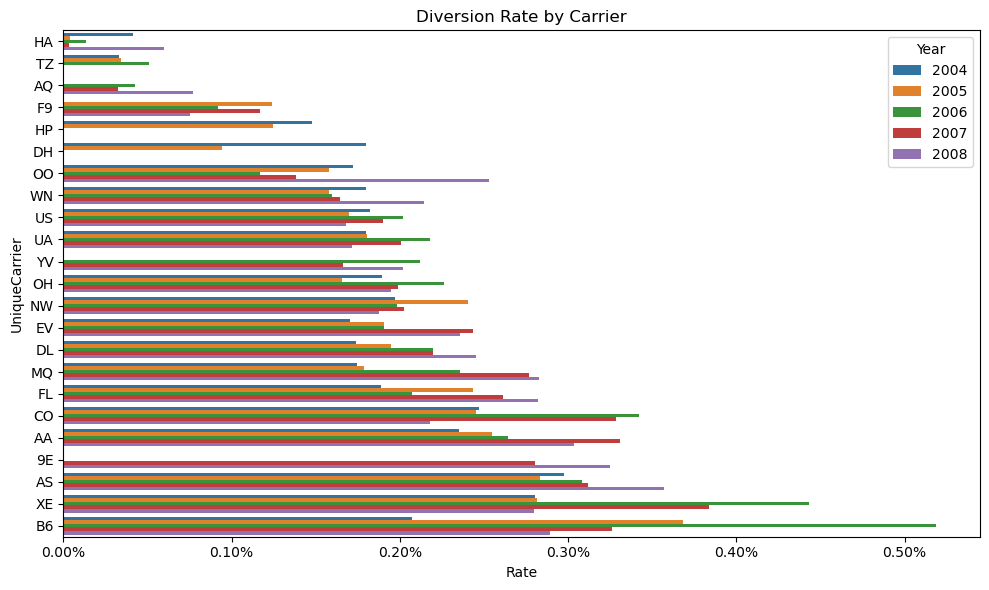

  Feature  Correlation
 Distance     0.017369
    Month    -0.000593
DayOfWeek    -0.000420
  DepHour    -0.000296


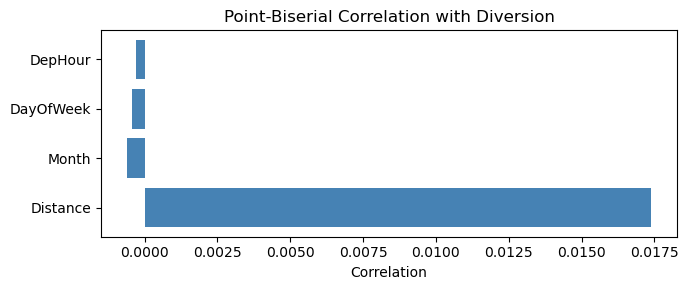

In [23]:
# Engineer DepHour (assuming CRSDepTime is available)
flights['DepHour'] = np.floor(flights['CRSDepTime'] / 100)
flights.loc[~flights['DepHour'].between(0, 23), 'DepHour'] = pd.NA

# Helper to compute diversion rate by grouping variables
def diversion_rate_by(df, group_vars):
    return (df.groupby(group_vars)
            .agg(Rate=('Diverted', lambda x: x.mean()),
                 Count=('Diverted', 'size'))
            .reset_index())

# 1. Diversion rate by Month, DayOfWeek, DepHour (across years)
dow_labels = {1:'Mon', 2:'Tue', 3:'Wed', 4:'Thu', 5:'Fri', 6:'Sat', 7:'Sun'}

for col, xlabel in [('Month', 'Month'), ('DayOfWeek', 'Day of Week'), ('DepHour', 'Departure Hour')]:
    eda = flights.dropna(subset=[col]).groupby(['Year', col])['Diverted'].mean().reset_index(name='Rate')
    fig, ax = plt.subplots(figsize=(10, 4))
    for yr, grp in eda.groupby('Year'):
        x = grp[col].map(dow_labels) if col == 'DayOfWeek' else grp[col]
        ax.plot(x, grp['Rate'], marker='o', label=str(yr))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.2%}'))
    ax.set_title(f'Diversion Rate by {xlabel}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Diversion Rate')
    ax.legend(title='Year')
    plt.tight_layout()
    plt.show()

# 2. Diversion rate by Carrier (only carriers with >1000 flights per year)
eda_carrier = (
    flights.groupby(['Year', 'UniqueCarrier'])
    .agg(Rate=('Diverted', 'mean'), Count=('Diverted', 'count'))
    .reset_index().query('Count > 1000')
)

#Plot
fig, ax = plt.subplots(figsize=(10, 6))
carrier_order = eda_carrier.groupby('UniqueCarrier')['Rate'].mean().sort_values().index
sns.barplot(data=eda_carrier, y='UniqueCarrier', x='Rate', hue='Year',
            order=carrier_order, ax=ax, palette='tab10')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2%}'))
ax.set_title('Diversion Rate by Carrier')
plt.tight_layout()
plt.show()

# 3. Point‑biserial correlations
features = ['Month', 'DayOfWeek', 'DepHour', 'Distance']
cor_df = (
    pd.DataFrame({f: [flights[f].astype('float64').corr(flights['Diverted'].astype('float64'))]
                  for f in features})
    .T.rename(columns={0: 'Correlation'}).rename_axis('Feature').reset_index()
    .sort_values('Correlation', key=abs, ascending=False)
)
print(cor_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(cor_df['Feature'], cor_df['Correlation'], color='steelblue')
ax.set_title('Point-Biserial Correlation with Diversion')
ax.set_xlabel('Correlation')
plt.tight_layout()
plt.show()

#### 2. Model pipeline
- to replicate the R logic
- filter year, select columns, drop missing information
- stratified sampling to take 20% of each class
- train and test
- create dummy variable but have to drop first to avoid multicollinearity

In [36]:
SAMPLE_FRAC = 0.20
TRAIN_PROP  = 0.80
THRESHOLD   = 0.5

year_list   = sorted(flights['Year'].dropna().unique())
all_results = []
perf_list   = []

for yr in year_list:
    print(f'\n══ Year: {int(yr)} ══════════════════════')

    # Prepare & stratified sample
    df = (
        flights[flights['Year'] == yr]
        [['Diverted', 'Month', 'DayOfWeek', 'DepHour', 'Distance', 'UniqueCarrier']]
        .dropna()
        .copy()
    )
    df['Diverted']  = df['Diverted'].astype(int)
    df['DepHour']   = df['DepHour'].astype(int)

    # Stratified sample preserving class ratio
    df = (
        df.groupby('Diverted', group_keys=False)
          .apply(lambda x: x.sample(frac=SAMPLE_FRAC, random_state=2195))
    )
    print(f'  Sample size: {len(df):,}  |  Diversion rate: {df["Diverted"].mean()*100:.3f}%')

    # 80/20 stratified train/test split
    train_df, test_df = train_test_split(
        df, test_size=1 - TRAIN_PROP,
        stratify=df['Diverted'], random_state=2195
    )
    print(f'  Train: {len(train_df):,}  |  Test: {len(test_df):,}')

    # Create dummy variables for UniqueCarrier
    train_df = pd.get_dummies(train_df, columns=['UniqueCarrier'], drop_first=True)
    test_df  = pd.get_dummies(test_df,  columns=['UniqueCarrier'], drop_first=True)

    # Ensure test set has same dummy columns as train set
    for col in set(train_df.columns) - set(test_df.columns):
        test_df[col] = 0
    test_df = test_df[train_df.columns]

    # Prepare X, y
    feature_cols = [c for c in train_df.columns if c != 'Diverted']
    X_train = train_df[feature_cols].astype(float)
    y_train = train_df['Diverted']
    X_test  = test_df[feature_cols].astype(float)
    y_test  = test_df['Diverted']

    # Add intercept for statsmodels
    X_train_const = sm.add_constant(X_train)
    X_test_const  = sm.add_constant(X_test)

    # Fit logistic regression on training set only
    try:
        model = sm.Logit(y_train, X_train_const).fit(disp=0)
    except Exception as e:
        print(f'  Warning: model failed for {int(yr)}: {e}. Skipping.')
        continue

    # Evaluate on test set
    y_pred_prob = model.predict(X_test_const)
    y_pred      = (y_pred_prob > THRESHOLD).astype(int)
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_prob)
    print(f'  Accuracy: {acc:.4f}  |  AUC: {auc:.4f}')

    # Extract coefficients with confidence intervals
    params       = model.params
    conf         = model.conf_int()
    conf.columns = ['conf_low', 'conf_high']
    coef_df = pd.DataFrame({
        'term':      params.index,
        'estimate':  params.values,
        'conf_low':  conf['conf_low'].values,
        'conf_high': conf['conf_high'].values
    })
    coef_df['Year']     = int(yr)
    coef_df['Accuracy'] = acc
    coef_df['AUC']      = auc
    all_results.append(coef_df)
    perf_list.append({'Year': int(yr), 'Accuracy': acc, 'AUC': auc})

# Combine results (outside the loop)
results = pd.concat(all_results, ignore_index=True)
perf_df = pd.DataFrame(perf_list)
print('\nDone.')


══ Year: 2004 ══════════════════════


/var/folders/r3/3qqhd4rd4995cjvl_0xbc8r40000gn/T/ipykernel_1913/1972587570.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=SAMPLE_FRAC, random_state=2195))


  Sample size: 1,425,854  |  Diversion rate: 0.193%
  Train: 1,140,683  |  Test: 285,171
  Accuracy: 0.9981  |  AUC: 0.6223

══ Year: 2005 ══════════════════════


/var/folders/r3/3qqhd4rd4995cjvl_0xbc8r40000gn/T/ipykernel_1913/1972587570.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=SAMPLE_FRAC, random_state=2195))


  Sample size: 1,428,120  |  Diversion rate: 0.196%
  Train: 1,142,496  |  Test: 285,624
  Accuracy: 0.9980  |  AUC: 0.6208

══ Year: 2006 ══════════════════════


...

/var/folders/r3/3qqhd4rd4995cjvl_0xbc8r40000gn/T/ipykernel_1913/1972587570.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=SAMPLE_FRAC, random_state=2195))


  Sample size: 1,490,643  |  Diversion rate: 0.231%
  Train: 1,192,514  |  Test: 298,129
  Accuracy: 0.9977  |  AUC: 0.6555

══ Year: 2008 ══════════════════════


/var/folders/r3/3qqhd4rd4995cjvl_0xbc8r40000gn/T/ipykernel_1913/1972587570.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=SAMPLE_FRAC, random_state=2195))


  Sample size: 477,844  |  Diversion rate: 0.237%
  Train: 382,275  |  Test: 95,569
  Accuracy: 0.9976  |  AUC: 0.6052

Done.


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


#### 3. Visualise results

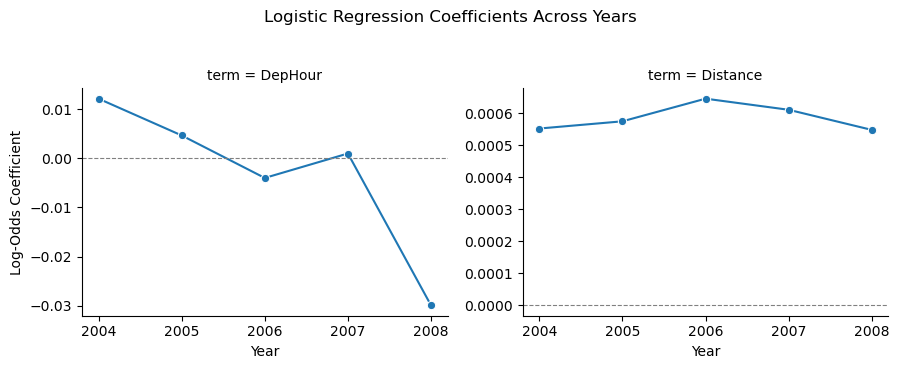

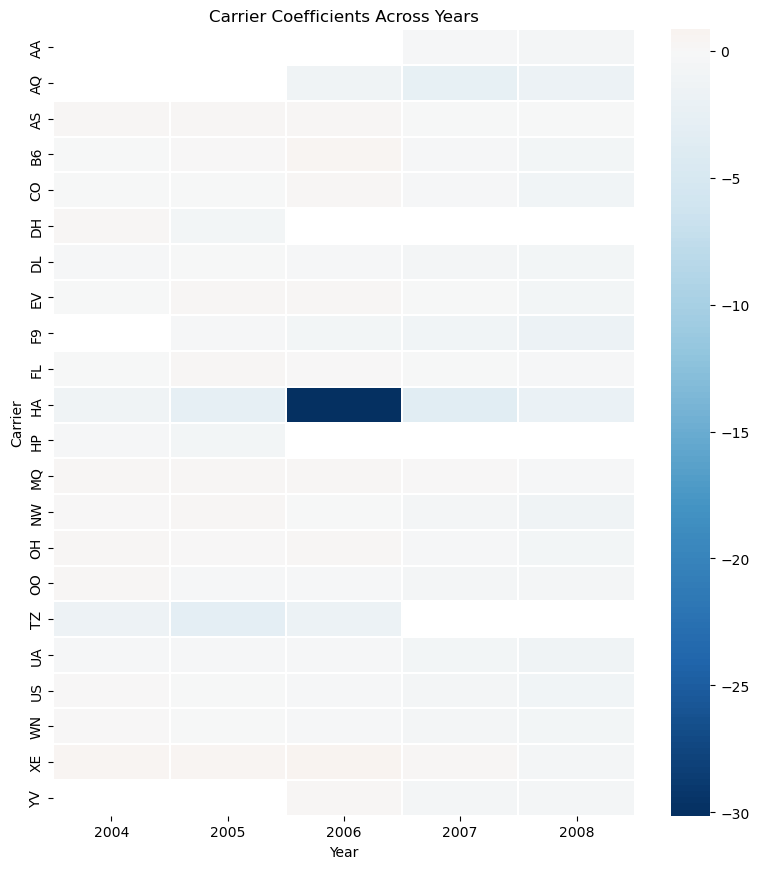

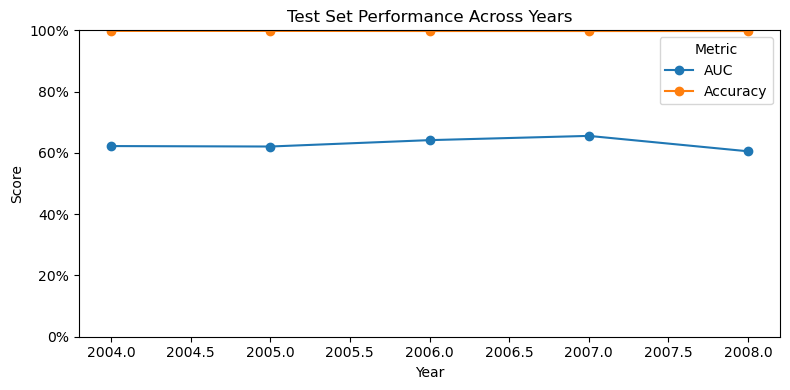

In [37]:
# 1. Numeric feature coefficients across years
numeric_terms = ['DepHour', 'Distance']
num_coefs = results[results['term'].isin(numeric_terms)].copy()

g = sns.relplot(
    data=num_coefs, x='Year', y='estimate',
    col='term', col_wrap=2, kind='line', marker='o',
    height=3.5, aspect=1.3,
    facet_kws={'sharey': False}
)
for ax in g.axes.flat:
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
g.set_axis_labels('Year', 'Log-Odds Coefficient')
g.fig.suptitle('Logistic Regression Coefficients Across Years', y=1.04)
g.tight_layout()
plt.show()

# Carrier coefficients heatmap
carrier_coefs = results[results['term'].str.startswith('UniqueCarrier_')].copy()
carrier_coefs['Carrier'] = carrier_coefs['term'].str.replace('UniqueCarrier_', '', regex=False)
pivot_carrier = carrier_coefs.pivot(index='Carrier', columns='Year', values='estimate')

fig, ax = plt.subplots(figsize=(8, max(5, len(pivot_carrier) * 0.4)))
sns.heatmap(pivot_carrier, ax=ax, cmap='RdBu_r', center=0,
            linewidths=0.3, linecolor='white')
ax.set_title('Carrier Coefficients Across Years')
plt.tight_layout()
plt.show()

# Model performance across years
perf_long = perf_df.melt(id_vars='Year', value_vars=['Accuracy', 'AUC'],
                         var_name='Metric', value_name='Score')
fig, ax = plt.subplots(figsize=(8, 4))
for metric, grp in perf_long.groupby('Metric'):
    ax.plot(grp['Year'], grp['Score'], marker='o', label=metric)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_ylim(0, 1)
ax.set_title('Test Set Performance Across Years')
ax.set_xlabel('Year')
ax.set_ylabel('Score')
ax.legend(title='Metric')
plt.tight_layout()
plt.show()

#### Conclusion for part c:
- EDA revelas the diversion across the different variables with certain airlines consistently showing higher rtes across all years
- distance & departure hour show stable coefficient signs across all years
- ACU scores reveal the models struggle to distinguish diverted from non-diverted flights due to class imbalance